# 问题描述

使用Python/C/C++/等来编写一个能解决如下杆件系统的有限元计算程序。

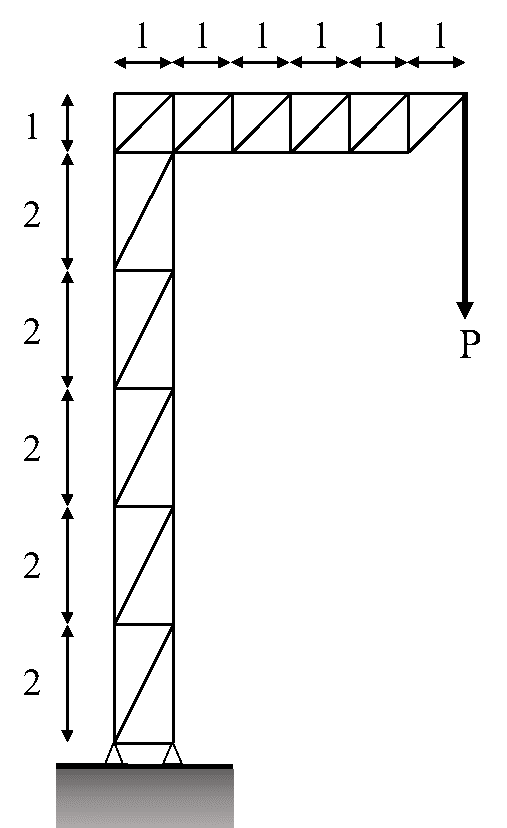

试编写有限元计算程序求解各个节点的位移、力、各单元的应力与应变。
（1）输入文件：
本次作业不指定输入文件，但需要输入文件。
（2）输出文件：
本次作业输出文件内容如下：
N (node number)   U (displacement of node)   F (external force of node)
1  xxx  xxx
2  xxx  xxx
...
E (element number)   Under Tension/Compression   Stress   Strain
1  Under Tension      xxx   xxx
2  Under Compression  xxx   xxx


# 前置处理

## 导入python第三方库

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import math

## 定义Element类

In [2]:
# 定义Element类，存储单元节点编号，单元的弹性模量、横截面积和长度信息
class Element:
    def __init__(self, n1, n2, stiff, S, L):
        self.node1 = n1
        self.node2 = n2
        self.stiffness = stiff
        self.area = S
        self.length = L

    # 生成k_e矩阵
    def Matrix(self, node):
        c = (node[self.node2 - 1][0] - node[self.node1 - 1][0]) / self.length
        s = (node[self.node2 - 1][1] - node[self.node1 - 1][1]) / self.length
        k = self.stiffness * self.area / self.length
        matrix = np.array(
            [
                [c**2, s * c, -(c**2), -s * c],
                [s * c, s**2, -s * c, -(s**2)],
                [-(c**2), -s * c, c**2, s * c],
                [-s * c, -(s**2), s * c, s**2],
            ]
        )
        matrix[:4, :4] *= k
        return matrix

    # 计算应变
    def Axial_stress(self, nodes, nodes_after):
        delta_length = math.sqrt(
            (nodes_after[self.node1 - 1][0] - nodes_after[self.node2 - 1][0]) ** 2
            + (nodes_after[self.node1 - 1][1] - nodes_after[self.node2 - 1][1]) ** 2
        ) - math.sqrt(
            (nodes[self.node1 - 1][0] - nodes[self.node2 - 1][0]) ** 2
            + (nodes[self.node1 - 1][1] - nodes[self.node2 - 1][1]) ** 2
        )
        strain = delta_length / self.length
        return self.stiffness * strain

## 读取文件

In [3]:
# 存储材料属性
material = [{}, {}, {}, {}]
# 存储杆单元
element = []
# 存储节点信息
nodes = []

with open("../../input/Truss 2.txt", "r") as f:
    lines = f.readlines()
    # 读取不同杆件的力学参数
    for i in range(4):
        tmp = lines[i].strip().split(" ")
        material[i] = {
            "stiffness": float(tmp[0]),
            "area": float(tmp[1]),
            "length": float(tmp[2]),
        }
    # 读取外力P
    F = lines[4].strip()
    # 将杆件的信息存储到element列表内
    for i in range(5, 48):
        element.append(
            Element(
                int(lines[i].strip().split(" ")[0]),
                int(lines[i].strip().split(" ")[1]),
                material[int(lines[i].strip().split(" ")[2]) - 1]["stiffness"],
                material[int(lines[i].strip().split(" ")[2]) - 1]["area"],
                material[int(lines[i].strip().split(" ")[2]) - 1]["length"],
            )
        )
    # 读取节点坐标
    for i in range(48, 71):
        nodes.append(
            [int(lines[i].strip().split(" ")[0]), int(lines[i].strip().split(" ")[1])]
        )

IndexError: list index out of range

# 问题求解

## 装配全局刚度矩阵$[K]$

In [ ]:
# 创建空矩阵
stiffnessMatrix = np.zeros((46, 46))
vector = np.zeros(4)

# 按杆进行全局刚度矩阵的装配
for bar in element:
    vector = [2 * bar.node1 - 1, 2 * bar.node1, 2 * bar.node2 - 1, 2 * bar.node2]
    for i in range(4):
        for j in range(4):
            stiffnessMatrix[vector[i] - 1][vector[j] - 1] += bar.Matrix(nodes)[i][j]
print(stiffnessMatrix)
print(np.linalg.det(stiffnessMatrix[-42:, -42:]))

## 求解控制方程
$\{F\}=[K]\{U\}$

In [ ]:
# 初始化F_a、F_c、U_c矩阵
F_aMatrix = np.zeros(42).T
F_aMatrix[41] = F
U_cMatrix = np.zeros(4).T

# 初始化U_a矩阵
U_aMatrix = np.dot(
    np.linalg.inv(stiffnessMatrix[-42:, -42:]),
    (F_aMatrix - np.dot(stiffnessMatrix[-42:, :4], U_cMatrix)),
)
print(U_aMatrix)

# 初始化F_c矩阵
F_cMatrix = np.dot(stiffnessMatrix[:4, :4], U_cMatrix) + np.dot(
    stiffnessMatrix[:4, -42:], U_aMatrix
)
print(F_cMatrix)

# 节点位移
nodes_delta = []
nodes_delta = np.concatenate((U_cMatrix.T, U_aMatrix.T))
print(nodes_delta)

# 节点力
nodes_force = []
nodes_force = np.concatenate((F_cMatrix.T, F_aMatrix.T))
print(nodes_force)

# 节点变形后坐标
nodes_after = []
for i in range(23):
    x = nodes[i][0] - nodes_delta[2 * i]
    y = nodes[i][1] - nodes_delta[2 * i + 1]
    nodes_after.append([x, y])

## 计算节点位移、最大拉压应力等

In [ ]:
# 最大垂直位移
Maximum_vertical_displacement = {
    "value": np.max(nodes_delta[1::2]),
    "ID": int((np.argwhere(nodes_delta == np.max(nodes_delta[1::2])) + 1)[0][0] / 2),
}
print(Maximum_vertical_displacement)

# 最大压应力和最大拉应力
stress = []
for bar in element:
    stress.append(bar.Axial_stress(nodes, nodes_after))

Maximum_tensile_stress = {
    "value": np.max(stress),
    "ID": int((np.argwhere(stress == np.max(stress)) + 1)[0][0]),
}
Minimum_tensile_stress = {
    "value": np.min(stress),
    "ID": int((np.argwhere(stress == np.min(stress)) + 1)[0][0]),
}
print(Maximum_tensile_stress)
print(Minimum_tensile_stress)

# 支座反力
Support_reaction = [
    {"F_x": F_cMatrix[0], "F_y": F_cMatrix[1]},
    {"F_x": F_cMatrix[2], "F_y": F_cMatrix[3]},
]
print(Support_reaction)

# 求解可视化

In [ ]:
# 变形前节点的位置
x_0 = [node[0] for node in nodes]
y_0 = [node[1] for node in nodes]

# 变形后节点的位置
x_1 = [node[0] for node in nodes_after]
y_1 = [node[1] for node in nodes_after]

fig, ax = plt.subplots()

# 绘制散点图
# ax.scatter(x_0, y_0)
# ax.scatter(x_1, y_1)

# 连线
for bar in element:
    ax.plot(
        [x_0[bar.node1 - 1], x_0[bar.node2 - 1]],
        [y_0[bar.node1 - 1], y_0[bar.node2 - 1]],
        "gray",
        label="before",
    )
for bar in element:
    if element.index(bar) == Maximum_tensile_stress["ID"] - 1:
        ax.plot(
            [x_1[bar.node1 - 1], x_1[bar.node2 - 1]],
            [y_1[bar.node1 - 1], y_1[bar.node2 - 1]],
            "green",
            label="max stress",
        )
    elif element.index(bar) == Minimum_tensile_stress["ID"] - 1:
        ax.plot(
            [x_1[bar.node1 - 1], x_1[bar.node2 - 1]],
            [y_1[bar.node1 - 1], y_1[bar.node2 - 1]],
            "red",
            label="min stress",
        )
    else:
        ax.plot(
            [x_1[bar.node1 - 1], x_1[bar.node2 - 1]],
            [y_1[bar.node1 - 1], y_1[bar.node2 - 1]],
            "black",
            label="after",
        )

ax.scatter(
    nodes_after[Maximum_vertical_displacement["ID"] - 1][0],
    nodes_after[Maximum_vertical_displacement["ID"] - 1][1],
)
arrow_props = dict(facecolor="red", arrowstyle="->")
ax.annotate(
    "",
    xy=(nodes_after[-1][0], nodes_after[-1][1] - 4),
    xytext=(nodes_after[-1][0], nodes_after[-1][1]),
    arrowprops=arrow_props,
)

# 设置坐标轴比例相同
ax.axis("equal")

ax.set_xlabel("X/m")
ax.set_ylabel("Y/m")
ax.grid()

ax.set_title("Schematic diagram before and after truss deformation")
plt.legend(
    handles=[
        plt.Line2D([], [], color="gray", label="before"),
        plt.Line2D([], [], color="black", label="after"),
        plt.Line2D([], [], color="blue", label="$\Delta y_{\max}$"),
        plt.Line2D([], [], color="green", label="$\sigma_{\max}$"),
        plt.Line2D([], [], color="red", label="$\sigma_{\min}$"),
    ]
)

plt.savefig("output.png")
plt.show()

# 生成output.txt

In [ ]:
with open("output.txt", "w") as f:
    f.write(
        "NODE"
        + "\t"
        + "U_x".ljust(15)
        + "\t"
        + "U_y".ljust(15)
        + "\t"
        + "F_x".ljust(15)
        + "\t"
        + "F_y".ljust(15)
        + "\n"
    )
    for node in nodes_after:
        f.write(
            str(nodes_after.index(node) + 1).ljust(4)
            + "\t"
            + str(nodes_delta[2 * nodes_after.index(node)])[:9].ljust(15)
            + "\t"
            + str(nodes_delta[2 * nodes_after.index(node)])[:9].ljust(15)
            + "\t"
            + str(nodes_force[2 * nodes_after.index(node)])[:9].ljust(15)
            + "\t"
            + str(nodes_force[2 * nodes_after.index(node) + 1])[:9].ljust(15)
            + "\n"
        )
    f.write(
        "Maximum vertical displacement:"
        + "\n"
        + "number:".ljust(9)
        + str(Maximum_vertical_displacement["ID"]).ljust(15)
        + "value:".ljust(9)
        + str(Maximum_vertical_displacement["value"])[:9].ljust(15)
        + "\n"
        + "Maximum tensile stress:"
        + "\n"
        + "number:".ljust(9)
        + str(Maximum_tensile_stress["ID"]).ljust(15)
        + "value:".ljust(9)
        + str(Maximum_tensile_stress["value"])[:9].ljust(15)
        + "\n"
        + "Maximum compressive stress:"
        + "\n"
        + "number:".ljust(9)
        + str(Minimum_tensile_stress["ID"]).ljust(15)
        + "value:".ljust(9)
        + str(Minimum_tensile_stress["value"])[:9].ljust(15)
        + "\n"
        + "Reaction forces at support nodes:"
        + "\n"
        + "F_x1:".ljust(9)
        + str(Support_reaction[0]["F_x"])[:9].ljust(15)
        + "F_y1:".ljust(9)
        + str(Support_reaction[0]["F_y"])[:9].ljust(15)
        + "\n"
        + "F_x2:".ljust(9)
        + str(Support_reaction[1]["F_x"])[:9].ljust(15)
        + "F_y2:".ljust(9)
        + str(Support_reaction[1]["F_y"])[:9].ljust(15)
    )

# 结论分析

通过编写简单的有限元程序求解二维桁架的变形使我对有限元方法的便捷性有了更新的认识。经过对比程序运算的结果与弹性力学理论解，可以得出相同的结果。程序求解的最大拉压应力和最大垂直位移符合一般的力学规律。